# Chapter 10: Clustering Techniques

**Book:** *scikit-learn Cookbook, Third Edition* – John Sukup  
**Chapter summary and practical examples**

Clustering is an **unsupervised learning** method. Instead of learning from known target labels, it groups observations according to similarities in their features. This chapter reviews common clustering methods, ways to assess their results, and practical considerations for choosing an algorithm.

The examples below are written in my own words and use small synthetic datasets so the main ideas can be explored without requiring an external dataset.

## Learning Objectives

By the end of this notebook, you should be able to:

- Explain how clustering differs from supervised learning.
- Apply K-means, agglomerative hierarchical clustering, and DBSCAN.
- Use internal and external metrics to assess cluster quality.
- Select an algorithm based on cluster shape, noise, scale, and dimensionality.
- Try spectral clustering and Gaussian Mixture Models (GMMs) for more complex structures.

## Environment Setup
We use scikit-learn for clustering and data generation, SciPy for dendrograms, and Matplotlib for visual inspection.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs, make_moons, make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

RANDOM_STATE = 2024

## 10.1 Introduction to Clustering

Clustering looks for groups that emerge from the feature values themselves. It can support tasks such as customer segmentation, exploratory analysis, and finding unusual observations. Because there are usually no target labels, the groups must be interpreted using domain knowledge as well as plots and metrics.

The chapter distinguishes three broad approaches:

- **Centroid-based:** represents groups by central points, as in K-means.
- **Connectivity-based:** builds groups by merging nearby observations, as in agglomerative clustering.
- **Density-based:** identifies dense regions and can leave sparse observations as noise, as in DBSCAN.

Feature scales matter for distance-based methods. Standardizing features is often a sensible starting point when variables use different units.

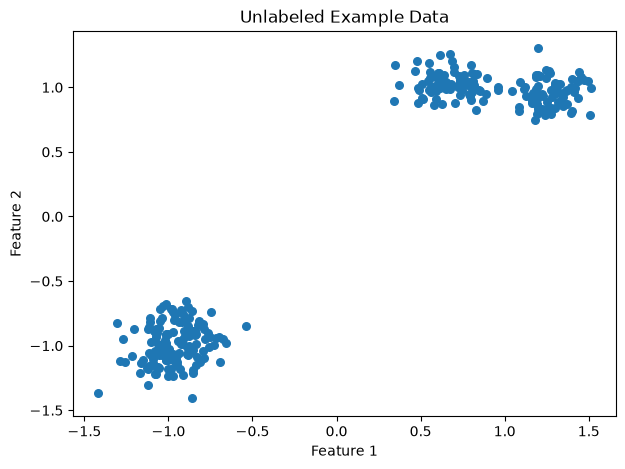

In [2]:
X_blobs, _ = make_blobs(
    n_samples=300, centers=4, cluster_std=0.60, random_state=RANDOM_STATE
)
X_blobs = StandardScaler().fit_transform(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], s=30)
plt.title("Unlabeled Example Data")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## 10.2 K-Means Clustering

K-means requires the number of clusters, `k`, to be specified. It assigns each observation to the nearest centroid, recalculates each centroid as the mean of its assigned points, and repeats until the assignments stabilize or the iteration limit is reached.

It is efficient and often works well when clusters are compact and roughly round. It can be less suitable for irregularly shaped groups, very different cluster sizes, or data containing substantial outliers.

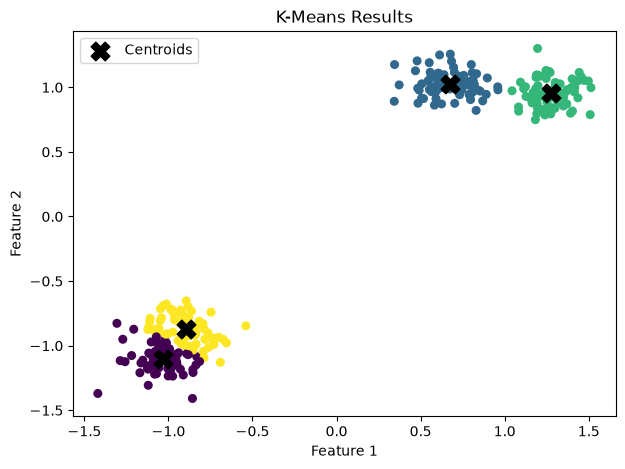

Inertia: 7.29


In [3]:
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
labels_kmeans = kmeans.fit_predict(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_kmeans, s=30, cmap="viridis")
plt.scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
    marker="X", s=180, c="black", label="Centroids"
)
plt.title("K-Means Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

print("Inertia:", round(kmeans.inertia_, 2))

### Estimating k with the Elbow Method

Inertia measures the total squared distance from observations to their assigned centroids. It normally decreases as `k` increases. The elbow method plots inertia across several values and looks for a point after which extra clusters give smaller improvements. The elbow is a guide, not a definitive answer.

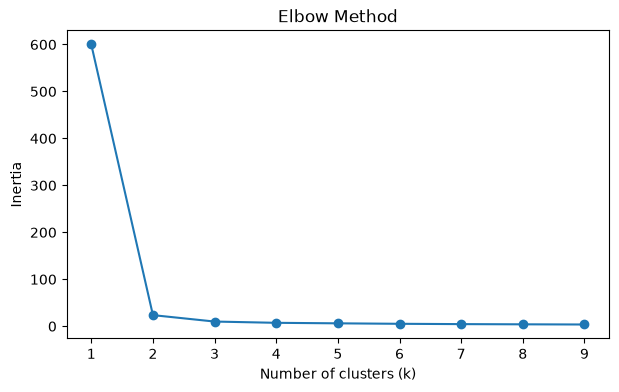

In [4]:
k_values = range(1, 10)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_blobs)
    inertias.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.show()

## 10.3 Hierarchical Clustering

Agglomerative clustering follows a bottom-up strategy: every observation begins in its own group, then the closest groups are repeatedly merged. The process can stop at a chosen number of clusters or based on a distance threshold.

The linkage rule determines how distance between groups is measured:

- **Ward:** merges groups to minimize the increase in within-cluster variance.
- **Complete:** uses the greatest pairwise distance between groups.
- **Average:** uses the average pairwise distance.
- **Single:** uses the smallest pairwise distance.

A dendrogram displays the sequence and distance of merges. It can help reveal natural separations, especially in smaller datasets.

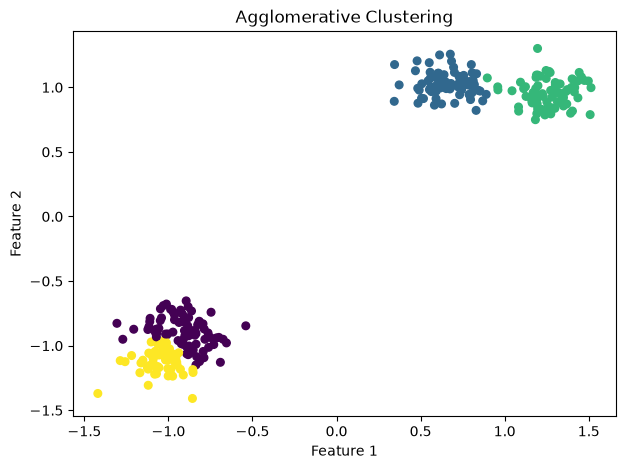

In [5]:
agg = AgglomerativeClustering(n_clusters=4, linkage="ward")
labels_agg = agg.fit_predict(X_blobs)

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_agg, s=30, cmap="viridis")
plt.title("Agglomerative Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

The following optional cell creates a dendrogram with SciPy. If SciPy is not installed, install it in your environment first. A dendrogram based on all 300 observations can be crowded, so a smaller sample is used for readability.

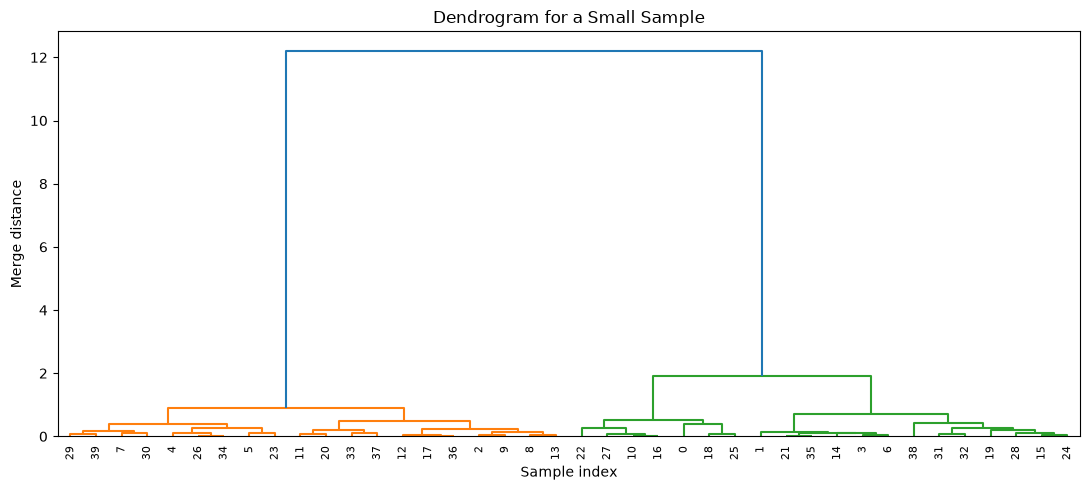

In [6]:
from scipy.cluster.hierarchy import linkage, dendrogram

small_sample = X_blobs[:40]
linked = linkage(small_sample, method="ward")

plt.figure(figsize=(11, 5))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for a Small Sample")
plt.xlabel("Sample index")
plt.ylabel("Merge distance")
plt.tight_layout()
plt.show()

## 10.4 Density-Based Clustering with DBSCAN

DBSCAN builds clusters from dense neighborhoods and does not require the number of clusters in advance. Its key parameters are:

- `eps`: the radius used to define a point's neighborhood.
- `min_samples`: the number of nearby points needed for a dense region.

It distinguishes **core points** in dense areas, **border points** near core points, and **noise points** that do not belong to a cluster. Noise is labeled `-1`. DBSCAN is especially useful for curved or irregular groups, but results can change considerably with parameter choices and feature scaling.

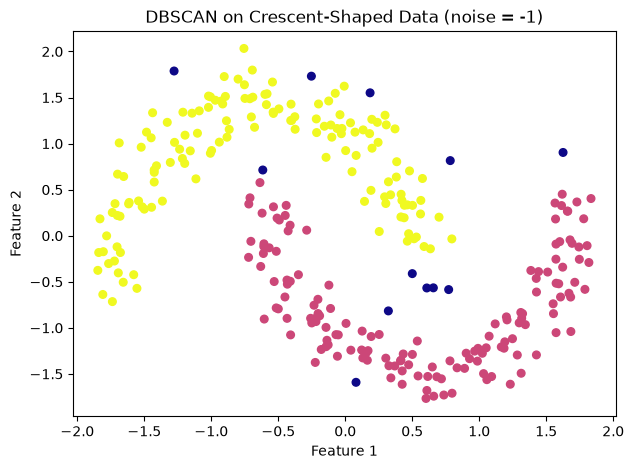

Cluster labels (including -1 for noise): [-1  0  1]
Number of noise points: 12


In [7]:
X_moons, _ = make_moons(n_samples=300, noise=0.10, random_state=RANDOM_STATE)
X_moons = StandardScaler().fit_transform(X_moons)

dbscan = DBSCAN(eps=0.25, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_moons)

plt.figure(figsize=(7, 5))
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=labels_dbscan, s=30, cmap="plasma")
plt.title("DBSCAN on Crescent-Shaped Data (noise = -1)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Cluster labels (including -1 for noise):", np.unique(labels_dbscan))
print("Number of noise points:", int(np.sum(labels_dbscan == -1)))

### Using a k-Distance Plot to Help Choose `eps`

One practical approach is to calculate each observation's distance to its `min_samples`-th nearest neighbor, sort those distances, and look for a sharp bend. The bend can suggest an `eps` value, but it should be tested against the resulting clusters and domain knowledge.

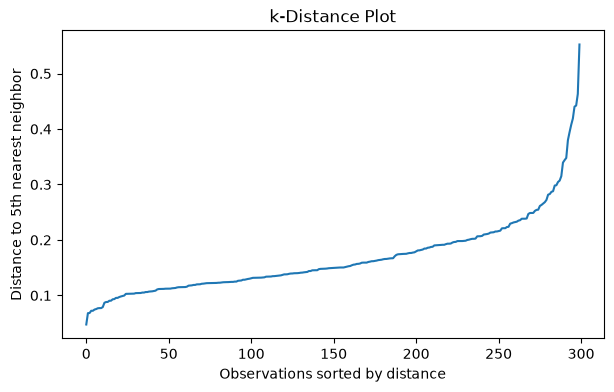

In [8]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_moons)
distances, _ = neighbors.kneighbors(X_moons)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_distances)
plt.title("k-Distance Plot")
plt.xlabel("Observations sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.show()

## 10.5 Cluster Evaluation Metrics

No single score completely describes clustering quality. The chapter introduces metrics that evaluate separation and compactness, and a metric that compares predicted groups with known labels when those labels are available.

- **Silhouette score:** ranges from -1 to 1; larger values generally indicate better-separated clusters.
- **Davies–Bouldin index:** lower values generally indicate more compact, distinct clusters.
- **Adjusted Rand Index (ARI):** compares predicted clusters with reference labels and adjusts for chance; 1 means perfect agreement, while values near 0 indicate agreement comparable to chance.

Silhouette and Davies–Bouldin do not require ground-truth labels. ARI does. Metrics should be considered alongside plots and the purpose of the analysis.

In [9]:
X_eval, y_true = make_blobs(
    n_samples=300, centers=4, cluster_std=0.60, random_state=RANDOM_STATE
)
model = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
y_pred = model.fit_predict(X_eval)

print(f"Silhouette score: {silhouette_score(X_eval, y_pred):.3f}")
print(f"Davies-Bouldin index: {davies_bouldin_score(X_eval, y_pred):.3f}")
print(f"Adjusted Rand Index: {adjusted_rand_score(y_true, y_pred):.3f}")

Silhouette score: 0.534
Davies-Bouldin index: 0.702
Adjusted Rand Index: 0.814


## 10.6 Choosing a Clustering Algorithm

Start by plotting the data and considering the shape of its groups, noise, dataset size, and feature dimensionality.

| Data characteristics | Possible starting point | Main consideration |
|---|---|---|
| Compact, convex groups | K-means | Choose `k`; sensitive to initialization |
| Small dataset where group hierarchy matters | Agglomerative clustering | Linkage and stopping criteria affect results |
| Irregular shapes and outliers | DBSCAN | Tune `eps` and `min_samples` |
| Large dataset with centroid-like groups | K-means or MiniBatchKMeans | Usually more scalable |
| Complex non-convex structure | Spectral clustering | Can require more computation |
| Probabilistic, overlapping groups | Gaussian Mixture Model | Choose component count and distribution assumptions |

For high-dimensional data, dimensionality reduction such as PCA may help reduce computation and make structure easier to detect. It is still important to check whether reducing dimensions preserves the distinctions relevant to the task.

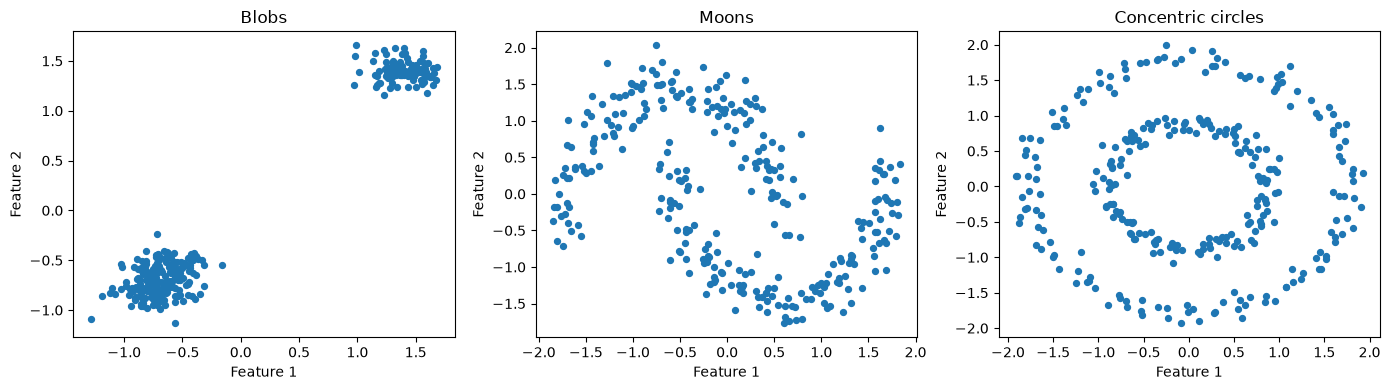

In [10]:
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=RANDOM_STATE)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=RANDOM_STATE)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=RANDOM_STATE)

datasets = [
    ("Blobs", StandardScaler().fit_transform(X_blobs)),
    ("Moons", StandardScaler().fit_transform(X_moons)),
    ("Concentric circles", StandardScaler().fit_transform(X_circles)),
]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, data) in zip(axes, datasets):
    ax.scatter(data[:, 0], data[:, 1], s=18)
    ax.set_title(name)
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

## 10.7 Advanced Clustering Techniques

### Spectral Clustering

Spectral clustering builds a similarity graph and uses its structure to identify groups. It can handle non-convex arrangements, such as crescent-shaped data, that are difficult for centroid-based methods. It generally requires a chosen number of clusters and may be more computationally demanding on large datasets.

### Gaussian Mixture Models (GMMs)

A GMM assumes the data is generated from a mixture of Gaussian distributions. Rather than assigning each point only by distance to a centroid, it models the probability that a point belongs to each component. This supports soft assignments and can represent elliptical clusters, although the model still depends on distribution assumptions and the number of components.

c:\Users\lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


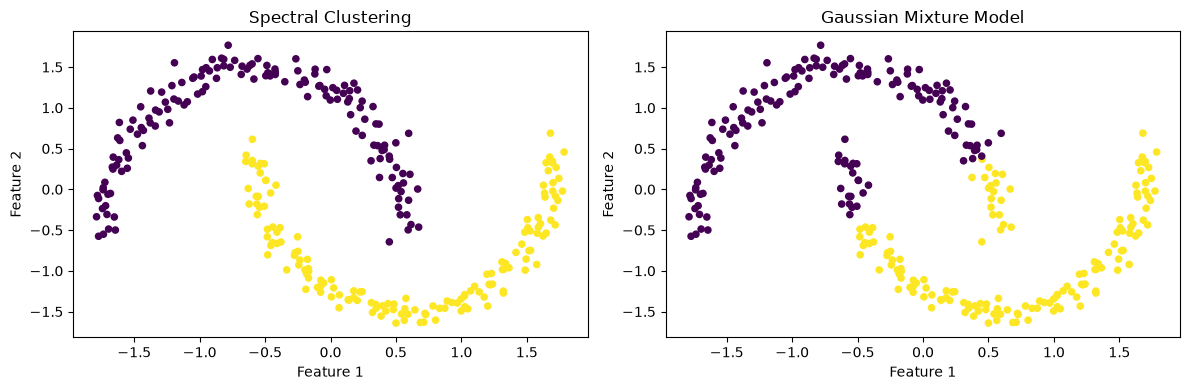

In [11]:
X_complex, _ = make_moons(n_samples=300, noise=0.05, random_state=RANDOM_STATE)
X_complex = StandardScaler().fit_transform(X_complex)

spectral = SpectralClustering(
    n_clusters=2, affinity="nearest_neighbors", random_state=RANDOM_STATE
)
spectral_labels = spectral.fit_predict(X_complex)

gmm = GaussianMixture(n_components=2, random_state=RANDOM_STATE)
gmm_labels = gmm.fit_predict(X_complex)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X_complex[:, 0], X_complex[:, 1], c=spectral_labels, s=20, cmap="viridis")
axes[0].set_title("Spectral Clustering")
axes[1].scatter(X_complex[:, 0], X_complex[:, 1], c=gmm_labels, s=20, cmap="viridis")
axes[1].set_title("Gaussian Mixture Model")
for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

## Practical Workflow

1. Inspect and visualize the original data.
2. Prepare features, including scaling when distances are meaningful.
3. Try one or more algorithms that match the apparent data structure.
4. Explore relevant parameters rather than relying on one default configuration.
5. Compare plots and suitable metrics; use external metrics only when reference labels exist.
6. Interpret the clusters in the context of the real problem.

## Chapter Summary

Clustering discovers groups without using target labels. K-means is a strong baseline for compact groups when the number of clusters can be estimated. Agglomerative clustering exposes a hierarchy of merges, while DBSCAN finds dense regions and can identify noise without a predefined cluster count. Silhouette score, Davies–Bouldin index, and ARI offer complementary evaluation perspectives. Spectral clustering and GMMs extend the toolbox to more complex structures and probabilistic membership.

The most important lesson is that algorithm choice depends on the data: inspect the feature space, understand the method's assumptions, and combine quantitative evaluation with domain interpretation.

**Reference:** John Sukup, *scikit-learn Cookbook, Third Edition*, Chapter 10, “Clustering Techniques.” The explanations in this notebook are paraphrased summaries, with compact illustrative examples.